# W3：特征工程、时序建模与分类


## 本周目标
把 W2 学到的线性回归接到一条**完整且不泄漏**的时序建模链路上，
并第一次接触分类任务（KNN / 逻辑回归 / 分类指标）。

## 数据与约定
- 数据：`data/PRSA_data_2010.1.1-2014.12.31.csv`（已在 `.gitignore`，不上传）
- 目标列：`pm2.5`
- 数值特征：`DEWP、TEMP、PRES、Iws、Is、Ir`
- 类别特征：`cbwd`
- 计划文件对照：`W3_01_特征工程.ipynb`、`W3_02_时序特征.ipynb`、`W3_03_时序基线.ipynb`、`W4_01_KNN.ipynb`、`W4_02_分类指标.ipynb`、`W4_03_逻辑回归_重污染分类.ipynb`

## 目录（按天）

| 章 | 内容 | 对应计划 | 建议日期 | 难度 |
|---|---|---|---|---|
| 一 | 特征工程：填充、缩放、独热、ColumnTransformer | D1 · W3_01 | 10-13 | 常规 |
| 二 | ★ 时序特征：周期编码、lag、rolling | D2 · W3_02 | 10-14 | 硬骨头 |
| 三 | ★ 时序划分、防泄漏、时序基线 | D3 · W3_03 | 10-15 | 硬骨头 |
| 四 | KNN 近邻（回归 + 分类） | D4 · W4_01 | 10-16 | 常规 |
| 五 | 分类指标：混淆矩阵、P/R/F1、ROC/AUC | D5 · W4_02 | 10-17 | 常规 |
| 六 | 逻辑回归：下一小时是否重污染 | D6 · W4_03 | 10-18 | 里程碑 |
| 七 | 本周小结与结果记录 | D6 提交 | 10-18 | — |


# 一、特征工程

**对应 D1（10-13）· 约 3h · 常规**


### 1.0 依赖导入（整周共用）


整周共用一份导入，后面章节不再重复 import。读 CSV 时先 `dropna(subset=["pm2.5"])`，目标缺失的行不能训练，特征缺失留到后面填。读完 `df.head()` 和 `df.info()` 确认行数约 43824、缺失分布。把数值列、类别列、目标列写成三个列表变量，后面每章复用。

In [1]:
from locale import normalize

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer,make_column_transformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn import set_config
set_config(display="text")
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.model_selection import (
    train_test_split,
    KFold,
    TimeSeriesSplit,
    cross_val_score,
    GridSearchCV,
)
from sklearn.metrics import (
    accuracy_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
)
import joblib
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.unicode_minus"] = False

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.unicode.east_asian_width", True)
RANDOM_STATE = 42
import sklearn
print("scikit-learn", sklearn.__version__)
DATA_PATH = "data/PRSA_data_2010.1.1-2014.12.31.csv"

df = pd.read_csv(DATA_PATH)
print("原始形状:", df.shape)
print("列名:", list(df.columns))
df = df.dropna(subset=["pm2.5"]).reset_index(drop=True)
print("dropna(pm2.5) 后:", df.shape)

df.head()

scikit-learn 1.9.1
原始形状: (43824, 13)
列名: ['No', 'year', 'month', 'day', 'hour', 'pm2.5', 'DEWP', 'TEMP', 'PRES', 'cbwd', 'Iws', 'Is', 'Ir']
dropna(pm2.5) 后: (41757, 13)


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,25,2010,1,2,0,129.0,-16,-4.0,1020.0,SE,1.79,0,0
1,26,2010,1,2,1,148.0,-15,-4.0,1020.0,SE,2.68,0,0
2,27,2010,1,2,2,159.0,-11,-5.0,1021.0,SE,3.57,0,0
3,28,2010,1,2,3,181.0,-7,-5.0,1022.0,SE,5.36,1,0
4,29,2010,1,2,4,138.0,-7,-5.0,1022.0,SE,6.25,2,0


## 1.2 数值列：中位数填充 + 标准化

数值列用 `SimpleImputer(strategy="median")` 填充，PM2.5 数据偏态明显，中位数更加合适。填充要和 `StandardScaler` 串成 `Pipeline`，不要先 `fit_transform` 整个数据集再切分，那是预处理泄漏。这里只搭一条支路，后面再合并。

In [2]:
pipe_num = make_pipeline(SimpleImputer(strategy="median"),StandardScaler())

## 1.3 风向 cbwd：独热编码

`OneHotEncoder(handle_unknown="ignore")`，不写这个参数，测试集出现训练集没见过的风向会报错。先 `df["cbwd"].value_counts()` 看有几类。风向不能直接编 0/1/2/3，那会引入人为的大小关系，而风向之间没有大小。

In [3]:
pipe_cat = make_pipeline(OneHotEncoder(handle_unknown="ignore"))

## 1.4 ColumnTransformer 合并两条支路

把 1.2 和 1.3 两条 Pipeline 塞进 `ColumnTransformer`，用 `("num", num_pipe, num_cols)` 的元组形式。列用名字指定，不用位置索引。一次 `fit` 出来的参数同时应用到训练和测试。

In [4]:
num = ['DEWP','TEMP','PRES','Iws','Is','Ir']
cat = ['cbwd']
pre = make_column_transformer((pipe_num, num),
                              (pipe_cat,cat)
 )

## 1.5 套 Pipeline 接线性回归

`make_pipeline(preprocessor, LinearRegression())`。想快速看有没有变好，先做一次随机切分的对照，正式评估留到第三章。W2 裸特征是 RMSE 82.3、R² 0.232，拿来比。

In [5]:
model = make_pipeline(pre,LinearRegression())
X = df[num+cat]
y = df['pm2.5']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=RANDOM_STATE)
model.fit(X_train,y_train)
print(model.score(X_test,y_test))
print(np.sqrt(mean_squared_error(y_test,model.predict(X_test))))

0.2546666594838334
81.04021173314078


## 1.6 查看转换后的特征名

`preprocessor.get_feature_names_out()` 确认独热后的列名和数值列顺序。特征顺序错乱是后面系数解释出错的常见原因。把结果和 `coef_` 配成表看谁影响最大。

In [6]:
pre.get_feature_names_out()

array(['pipeline-1__DEWP', 'pipeline-1__TEMP', 'pipeline-1__PRES',
       'pipeline-1__Iws', 'pipeline-1__Is', 'pipeline-1__Ir',
       'pipeline-2__cbwd_NE', 'pipeline-2__cbwd_NW',
       'pipeline-2__cbwd_SE', 'pipeline-2__cbwd_cv'], dtype=object)

# 二、★ 时序特征

**对应 D2（10-14）· 3.5–4.5h · 硬骨头（视频没讲，需自学）**

## 2.1 按时间排序、建时间索引

用 `pd.to_datetime` 把 year/month/day/hour 拼成 `datetime` 列，然后 `set_index` 或至少 `sort_values`。lag/rolling 完全依赖行的先后顺序，顺序错了整个第二章都错。检查首尾时间是否为 2010-01-01 00:00 和 2014-12-31 23:00，以及逐小时是否连续。

In [7]:
df['datetime'] = pd.to_datetime(df[['year','month','day','hour']])
print(df.head())
df = df.set_index('datetime')
df.shape

   No  year  month  day  hour  pm2.5  DEWP  TEMP    PRES cbwd   Iws  Is  Ir            datetime
0  25  2010      1    2     0  129.0   -16  -4.0  1020.0   SE  1.79   0   0 2010-01-02 00:00:00
1  26  2010      1    2     1  148.0   -15  -4.0  1020.0   SE  2.68   0   0 2010-01-02 01:00:00
2  27  2010      1    2     2  159.0   -11  -5.0  1021.0   SE  3.57   0   0 2010-01-02 02:00:00
3  28  2010      1    2     3  181.0    -7  -5.0  1022.0   SE  5.36   1   0 2010-01-02 03:00:00
4  29  2010      1    2     4  138.0    -7  -5.0  1022.0   SE  6.25   2   0 2010-01-02 04:00:00


(41757, 13)

## 2.2 时间特征：月、小时的 sin/cos 周期编码

23 点和 0 点在时间上相邻，但编号差 23，直接当数值喂模型会被当成很远。用 sin 和 cos 两个坐标把周期量映射到圆上，相邻点就真的相邻。月份 T=12，小时 T=24。保留原始整数列方便画图。

In [8]:
df['hour_sin'] = np.sin(2*np.pi*df['hour']/24)
df['hour_cos'] = np.cos(2*np.pi*df['hour']/24)

## 2.3 滞后特征 lag1、lag24

`shift(1)` 得到上一小时，`shift(24)` 得到昨天同一时刻。lag1 通常是 PM2.5 预测里最强的单变量，污染是连续的。shift 之后前 1 行和前 24 行必然是 NaN，不能填 0，那等于伪造「上一小时是 0」这个强错误信号。可以试 `shift(2)`、`shift(48)`，但要留意特征膨胀。

In [9]:
df['lag1'] =df['pm2.5'].shift(1)
df['lag24'] =df['pm2.5'].shift(24)

## 2.4 滚动特征：先 shift 再 rolling

顺序是 `df["pm2.5"].shift(1).rolling(24).mean()`，不是先 rolling 再 shift。直接 rolling 时第 t 行窗口包含第 t 行自己，等于把答案混进特征。先 shift 把当前行推出窗口，才是真正的过去 24 小时。至少做 `roll_mean_24` 和 `roll_std_24`，标准差代表污染稳定性。`roll_max_24` 在预警场景比均值更敏感。

In [10]:
df['roll_mean_3'] = df['pm2.5'].shift(1).rolling(3).mean()
df['roll_mean_24'] = df['pm2.5'].shift(1).rolling(24).mean()
df['roll_std_24'] = df['pm2.5'].shift(1).rolling(24).std()

## 2.5 特征表汇总与缺失处理

NaN 分三类。lag/rolling 算不出来的构造缺失要 `dropna`。气象特征的原始缺失用中位数 `fillna`，类别的用众数 `mode()[0]`。标签 `pm2.5` 缺失只能删行，顺序是先 dropna 构造缺失再填原始缺失。

In [11]:
feat_cols = ['lag1','lag24','roll_mean_3','roll_mean_24','roll_std_24','hour_sin','hour_cos']+num+cat
construct_cols = ['lag1','lag24','roll_mean_3','roll_mean_24','roll_std_24']

print(df[construct_cols].isna().sum())
print(df[num+cat+['pm2.5']].isna().sum())

feat = df.dropna(subset=construct_cols)

for c in num:
    feat[c] = feat[c].fillna(feat[c].median())
for c in cat:
    feat[c] = feat[c].fillna(feat[c].mode()[0])
print(feat[feat_cols].isna().sum())


lag1             1
lag24           24
roll_mean_3      3
roll_mean_24    24
roll_std_24     24
dtype: int64
DEWP     0
TEMP     0
PRES     0
Iws      0
Is       0
Ir       0
cbwd     0
pm2.5    0
dtype: int64
lag1            0
lag24           0
roll_mean_3     0
roll_mean_24    0
roll_std_24     0
hour_sin        0
hour_cos        0
DEWP            0
TEMP            0
PRES            0
Iws             0
Is              0
Ir              0
cbwd            0
dtype: int64


# 三、★ 时序划分、防泄漏与时序基线

**对应 D3（10-15）· 3.5–4.5h · 硬骨头**

## 3.1 按时间切分（2010–2013 训练 / 2014 测试）

按时间切，2010-2013 训练，2014 测试，不用 `train_test_split`。随机切分等于拿未来预测过去，真实场景里只有过去的数据。切完打印两个集合的时间范围和行数，确认没有重叠。切分要在特征构造之后、模型 fit 之前，标准化只在训练集上 fit。

In [12]:
train = feat[feat.index.year<=2013]
test = feat[feat.index.year==2014]

## 3.2 持久性基线（Persistence Baseline）

持久性基线是「预测下一小时 = 当前小时的值」，直接把 `lag1` 当预测值，不训练任何模型。复杂模型打不过它就没有意义。算 RMSE 和 R² 记进结果表，后面所有模型跟它比。它的 R² 可能不低，因为 lag1 自相关很强。

In [13]:
pred =test['lag1']
Baseline_rmse = np.sqrt(mean_squared_error(test['pm2.5'],pred))
Baseline_score = r2_score(test['pm2.5'],pred)
print(Baseline_score)
print(Baseline_rmse)


0.9439790683721084
22.136457386885123


## 3.3 线性回归 + TimeSeriesSplit

`TimeSeriesSplit(n_splits=5)` 把时间轴切 5 段，每折用前面的训练、紧跟其后的验证，不跨时间打乱。W2 用的是 `KFold(shuffle=True)`，五折 R² 都在 0.23-0.24，现在换特征又换切法，分数变化很大。

In [14]:
Xtrain = train[feat_cols]
ytrain = train['pm2.5']
Xtest = test[feat_cols]
ytest = test['pm2.5']

model.fit(Xtrain,ytrain)
pred_test = model.predict(Xtest)
Test_rmse = np.sqrt(mean_squared_error(ytest,pred_test))
Test_score = r2_score(ytest,pred_test)
print(Test_score)
print(Test_rmse)

0.22868544682325376
82.13886909670504


## 3.4 随机切分 vs 时序切分对比

同一套特征同一个模型，只换切分方式，两组 RMSE 和 R² 并排打印。预期随机切分明显更高。

In [15]:
Xa,Xb,ya,yb = train_test_split(feat[feat_cols],feat['pm2.5'],test_size=0.2,random_state=RANDOM_STATE)
model2 = make_pipeline(pre,LinearRegression())
model2.fit(Xa,ya)
Rand_rmse = np.sqrt(mean_squared_error(yb,model2.predict(Xb)))
Rand_score = r2_score(yb,model2.predict(Xb))
print(Rand_score)
print(Rand_rmse)
print(Test_score)
print(Test_rmse)

0.2618304869768793
79.46855695813254
0.22868544682325376
82.13886909670504


# 四、KNN 近邻

**对应 D4（10-16）· 约 3h · 常规**

## 4.1 iris：不同 k 的训练/测试误差曲线

先用 iris 把 k 值行为看清楚再上 PM2.5。遍历 k=1~20，每次记训练集和测试集准确率画两条线。k=1 时训练 100% 测试偏低是过拟合，噪声也被当成规律。k 变大训练降、测试先升后降，中间有最优 k。k 很大两边都低是欠拟合，等于只看全局多数类。

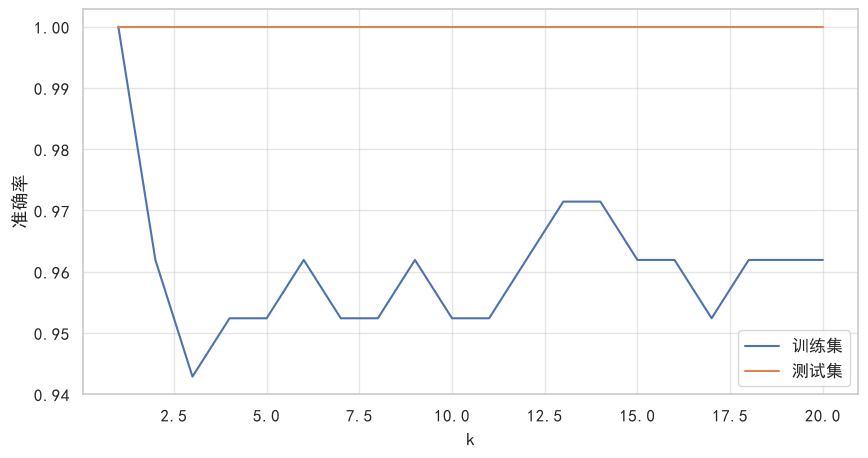

In [16]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X, y = load_iris(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42)

ks = range(1, 21)
tr_acc, te_acc = [], []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(X_tr, y_tr)
    tr_acc.append(accuracy_score(y_tr, m.predict(X_tr)))
    te_acc.append(accuracy_score(y_te, m.predict(X_te)))

plt.plot(ks, tr_acc, label="训练集")
plt.plot(ks, te_acc, label="测试集")
plt.xlabel("k"); plt.ylabel("准确率"); plt.legend()

## 4.2 PM2.5：KNN 回归（Pipeline 内先标准化）

KNN 基于距离，TEMP 范围约 -20~40、PRES 约 1000~1040、pm2.5 可能上千，不标准化的话距离几乎由数值大的列决定。一定要 `make_pipeline(StandardScaler(), KNeighborsRegressor())`，不要手动 `scaler.fit_transform` 之后再切分。先用 `n_neighbors=5` 跑通，和持久性基线、线性回归比。

In [17]:
pipe_knn = make_pipeline(pre,KNeighborsRegressor(n_neighbors=5))
pipe_knn.fit(Xtest, ytest)
Knn_rmse = np.sqrt(mean_squared_error(ytest,pipe_knn.predict(Xtest)))
Knn_score = r2_score(ytest,pipe_knn.predict(Xtest))
print('基线      ', Baseline_rmse, Baseline_score)
print('线性回归  ', Test_rmse, Test_score)
print('KNN回归   ', Knn_rmse, Knn_score)

基线       22.136457386885123 0.9439790683721084
线性回归   82.13886909670504 0.22868544682325376
KNN回归    52.205996149343534 0.6884162057784786


## 4.3 网格搜索选 k

`GridSearchCV` 搜 `n_neighbors`的合适值。默认 cv 是随机 KFold，时序任务要显式传 `cv=TimeSeriesSplit(3)`，否则引入时间泄漏。搜完打印 `best_params_` 和 `best_score_`，再在 2014 测试集上评估。

In [18]:
grid = GridSearchCV(pipe_knn, param_grid={'kneighborsregressor__n_neighbors':range(1,100)}, cv = TimeSeriesSplit(3),scoring='neg_mean_squared_error')
grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

{'kneighborsregressor__n_neighbors': 98}
-6111.571590998542


## 4.4 与线性时序基线对比

In [19]:
Knn_rmse = np.sqrt(mean_squared_error(ytest, pipe_knn.predict(Xtest)))
Knn_score = r2_score(ytest, pipe_knn.predict(Xtest))

best_knn = grid.best_estimator_
best_knn_rmse = np.sqrt(mean_squared_error(ytest, best_knn.predict(Xtest)))
best_knn_score = r2_score(ytest, best_knn.predict(Xtest))

compare = pd.DataFrame({
    '模型': ['持久性基线(lag1)', '线性回归(时序特征)', 'KNN(k=5)', f'KNN(k={grid.best_params_["kneighborsregressor__n_neighbors"]})'],
    'RMSE': [Baseline_rmse, Test_rmse, Knn_rmse, best_knn_rmse],
    'R2':   [Baseline_score, Test_score, Knn_score, best_knn_score],
})
compare['RMSE'] = compare['RMSE'].round(2)
compare['R2'] = compare['R2'].round(4)
compare

,模型,RMSE,R2
0,持久性基线(lag1),22.14,0.9440
1,线性回归(时序特征),82.14,0.2287
2,KNN(k=5),52.21,0.6884
3,KNN(k=98),75.97,0.3401


## 4.5 保存并重新加载模型

`joblib.dump` 和 `joblib.load`，加载后重新 predict 一遍确认一致。

In [20]:
import os
import joblib
os.makedirs("models", exist_ok=True)
joblib.dump(best_knn, "models/knn_pm25.joblib")
knn_loaded = joblib.load("models/knn_pm25.joblib")
pred_before = best_knn.predict(Xtest)
pred_after = knn_loaded.predict(Xtest)
print("预测完全一致:", np.allclose(pred_before, pred_after))

预测完全一致: True


## 开始之前，先清一次变量

感觉在练习中自己给变量起名起的太乱了，从day5开始变量搞得我头晕了,感觉之后这点还是要改，里我先把前面的捋一遍，把没用的变量名全丢了

In [21]:
drop_knn_reg = ['pipe_knn', 'Knn_rmse', 'Knn_score',
                'grid', 'best_knn', 'best_knn_rmse', 'best_knn_score']
drop_joblib = ['knn_loaded', 'pred_before', 'pred_after']
drop_ch1 = ['X', 'y', 'X_train', 'X_test', 'y_train', 'y_test', 'model']

removed = []
for v in drop_knn_reg + drop_joblib + drop_ch1:
    if v in globals():
        del globals()[v]
        removed.append(v)
print('已删除:', removed)
keep = ['feat', 'train', 'test', 'pre', 'Xtrain', 'ytrain', 'Xtest', 'ytest',
        'Baseline_rmse', 'Baseline_score', 'Test_rmse', 'Test_score']
print('保留:', [v for v in keep if v in globals()])

已删除: ['pipe_knn', 'Knn_rmse', 'Knn_score', 'grid', 'best_knn', 'best_knn_rmse', 'best_knn_score', 'knn_loaded', 'pred_before', 'pred_after', 'X', 'y', 'X_train', 'X_test', 'y_train', 'y_test', 'model']
保留: ['feat', 'train', 'test', 'pre', 'Xtrain', 'ytrain', 'Xtest', 'ytest', 'Baseline_rmse', 'Baseline_score', 'Test_rmse', 'Test_score']


---

# 五、分类指标：混淆矩阵 / P / R / F1 / ROC

**对应 D5（10-17）· 约 3h · 常规（周六，可用整块时间）**

## 5.1 构造重污染标签（pm2.5 ≥ 150）

`label = (df["pm2.5"] >= 150).astype(int)`。第一件事是 `label.value_counts(normalize=True)` 看分布，README 里算过重污染约占 20%，样本不平衡直接决定下面看哪些指标。不平衡数据下 accuracy 会骗人，80% 是 0 时永远预测 0 就有 80% 准确率，但一个重污染都抓不到，所以要 P/R/F1/ROC。

In [22]:
feat['label'] = (feat['pm2.5'] >= 150).astype(int)
print('占比:')
print(feat['label'].value_counts(normalize=True).round(4))
train = feat[feat.index.year <= 2013]
test = feat[feat.index.year == 2014]

占比:
label
0    0.7824
1    0.2176
Name: proportion, dtype: float64


## 5.1b 补一个覆盖全部特征的预处理

第一章的 pre 只接收 num（6 个气象列）和 cat（cbwd）。ColumnTransformer 只会挑选参数里列出的列，其余列被丢了。
其实我也是做完以后总结才发现的

pre 处理 train[feat_cols] 时，lag1、lag24、roll_mean_3、roll_mean_24、roll_std_24、hour_sin、hour_cos 这 7 列全被扔掉，模型实际只看到 10 列。

不报错，但第二章造的所有时序特征都没用上。

In [23]:
num_all = construct_cols + ['hour_sin', 'hour_cos'] + num
pre_all = make_column_transformer((pipe_num, num_all),
                                  (pipe_cat, cat))

## 5.2 混淆矩阵与 classification_report

用第四章的 KNN 换成 `KNeighborsClassifier` 拿到 `y_pred`。重污染预警场景下 FN 漏报比 FP 误报代价大得多，所以更在乎 recall。

混淆矩阵 [[TN FP] [FN TP]]:
[[6660  241]
 [ 265 1495]]

TN=6660  FP=241  FN=265  TP=1495
真实重污染共 1760 个，漏掉 265 个，漏报率 15.06%


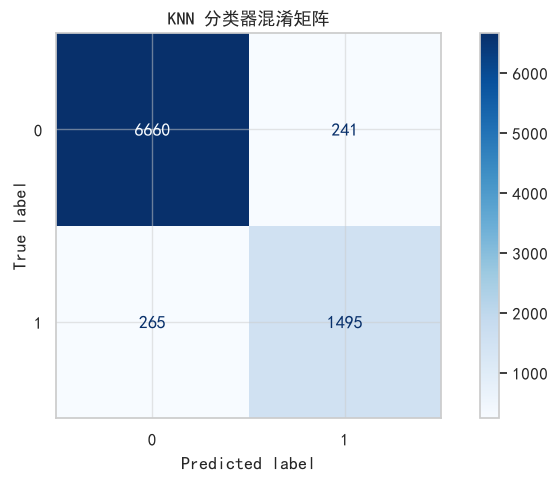

In [24]:
cls_model = make_pipeline(pre_all, KNeighborsClassifier(n_neighbors=5))
cls_model.fit(train[feat_cols], train['label'])

y_pred = cls_model.predict(test[feat_cols])
y_true = test['label'].values

cm = confusion_matrix(y_true, y_pred)
print('混淆矩阵 [[TN FP] [FN TP]]:')
print(cm)

tn, fp, fn, tp = cm.ravel()
print()
print('TN=%d  FP=%d  FN=%d  TP=%d' % (tn, fp, fn, tp))
print('真实重污染共 %d 个，漏掉 %d 个，漏报率 %.2f%%' % (fn+tp, fn, fn/(fn+tp)*100))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, cmap='Blues')
plt.title('KNN 分类器混淆矩阵')
plt.show()

## 5.3 ROC 曲线与 AUC

需要概率输出 `model.predict_proba(X)[:, 1]`，不是 `predict()`。`roc_curve(y, proba)` 得到不同阈值下的 FPR 和 TPR，画出来。图上画一条对角线当参照。

[0. 0. 0. ... 0. 0. 0.]
AUC = 0.9665


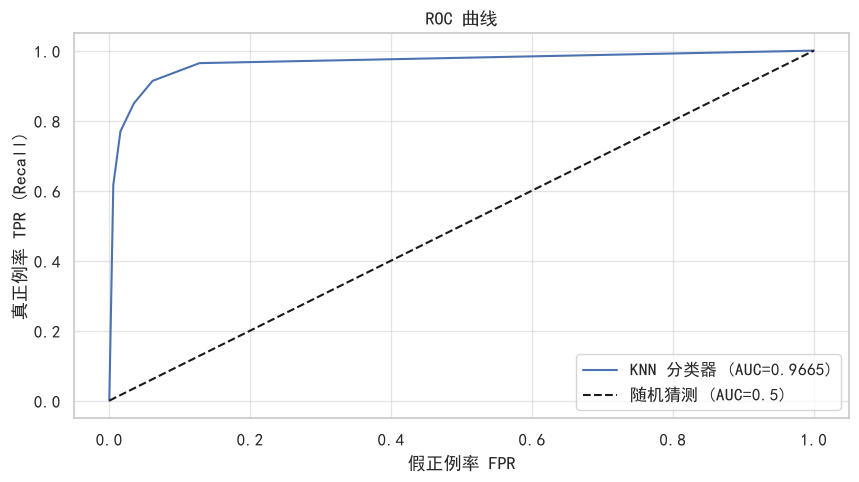

In [25]:
proba = cls_model.predict_proba(test[feat_cols])[:, 1]
#proba = cls_model.predict_proba(test[feat_cols])
print(proba)
fpr, tpr, thresholds = roc_curve(y_true, proba)
auc_knn = roc_auc_score(y_true, proba)
print('AUC = %.4f' % auc_knn)
plt.plot(fpr, tpr, label='KNN 分类器 (AUC=%.4f)' % auc_knn)
plt.plot([0, 1], [0, 1], 'k--', label='随机猜测 (AUC=0.5)')
plt.xlabel('假正例率 FPR')
plt.ylabel('真正例率 TPR (Recall)')
plt.title('ROC 曲线')
plt.legend()
plt.show()

## 5.4 调整阈值观察精确率/召回率

遍历 0.1~0.9，每个阈值算 precision/recall/f1 画三条曲线。规律是阈值升高 precision 升 recall 降，反之亦然。既然漏报代价大，应该把阈值调低来换更高 recall。

   阈值  Precision  Recall      F1
0   0.1     0.6578  0.9642  0.7820
1   0.2     0.7913  0.9136  0.8481
2   0.3     0.7913  0.9136  0.8481
3   0.4     0.8612  0.8494  0.8553
4   0.5     0.8612  0.8494  0.8553
5   0.6     0.9255  0.7693  0.8402
6   0.7     0.9255  0.7693  0.8402
7   0.8     0.9653  0.6159  0.7520
8   0.9     0.9653  0.6159  0.7520


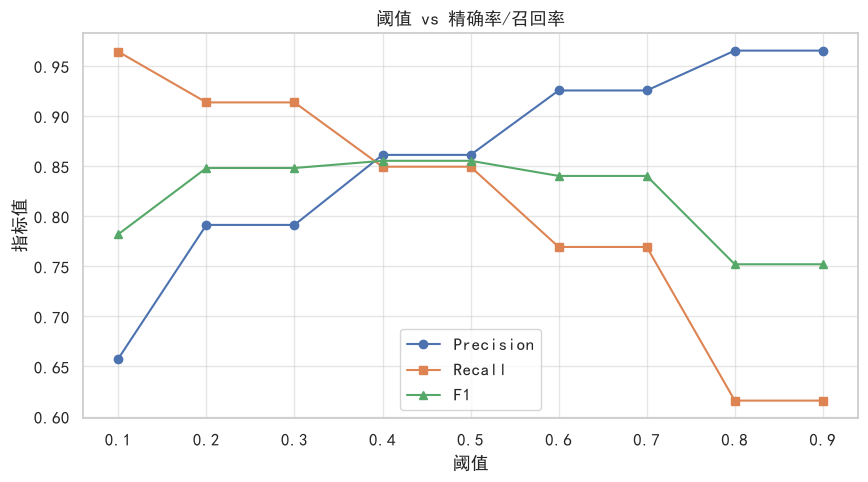

In [26]:
rows = []
for t in np.arange(0.1, 0.95, 0.1):
    yp = (proba > t).astype(int)
    rows.append([round(t, 2),
                 round(precision_score(y_true, yp, zero_division=0), 4),
                 round(recall_score(y_true, yp, zero_division=0), 4),
                 round(f1_score(y_true, yp, zero_division=0), 4)])

thr_df = pd.DataFrame(rows, columns=['阈值', 'Precision', 'Recall', 'F1'])
print(thr_df)

plt.plot(thr_df['阈值'], thr_df['Precision'], marker='o', label='Precision')
plt.plot(thr_df['阈值'], thr_df['Recall'], marker='s', label='Recall')
plt.plot(thr_df['阈值'], thr_df['F1'], marker='^', label='F1')
plt.xlabel('阈值')
plt.ylabel('指标值')
plt.title('阈值 vs 精确率/召回率')
plt.legend()
plt.show()

# 六、逻辑回归：下一小时是否重污染

**对应 D6（10-18）· 3–3.5h · 里程碑 · 第 1 次集中提交 W3–W4**

## 6.1 逻辑回归 Pipeline

`make_pipeline(preprocessor, LogisticRegression(max_iter=1000))`。`max_iter` 调大是因为默认 100 常常不收敛报警告。试试 `class_weight="balanced"`，平衡一下各特征的权重，提升 recall 降低 precision

In [27]:
pipe_log = make_pipeline(pre_all,LogisticRegression(max_iter=1000,class_weight='balanced'))
pipe_log.fit(train[feat_cols], train['label'])
names = pipe_log.named_steps["columntransformer"].get_feature_names_out()
coef  = pipe_log.named_steps["logisticregression"].coef_[0]
top = sorted(zip(names, coef), key=lambda x: -abs(x[1]))[:8]
print(top)

[('pipeline-1__lag1', np.float64(7.574178086669801)), ('pipeline-1__roll_mean_3', np.float64(-1.683229025199338)), ('pipeline-2__cbwd_NW', np.float64(-0.96771031885878)), ('pipeline-1__TEMP', np.float64(-0.8028795460156817)), ('pipeline-1__DEWP', np.float64(0.5112907931953653)), ('pipeline-2__cbwd_NE', np.float64(-0.46840459256549644)), ('pipeline-2__cbwd_SE', np.float64(-0.3175094960172556)), ('pipeline-1__roll_mean_24', np.float64(0.2993207330559851))]


## 6.2 混淆矩阵 / 分类报告 / ROC

和第五章大差不差，逻辑回归的 AUC 通常更稳，而且可解释，`coef_` 能直接看每个特征的方向和大小。重点看 `lag1`、`roll_mean_24` 的系数，应该是强正相关，过去高现在也容易高。

In [28]:
y_log_pred = pipe_log.predict(test[feat_cols])
cm_log = confusion_matrix(y_true, y_log_pred)
tn_log, fp_log, fn_log, tp_log = cm_log.ravel()
proba_log = pipe_log.predict_proba(test[feat_cols])[:, 1]
#本来在这里想去比召回率，但发现knn里的阈值取不到0.5，那我就用AUC去比较两个模型
auc_log = roc_auc_score(y_true, proba_log)
print('AUC = %.4f' % auc_log)

AUC = 0.9893


## 6.3 调节正则参数 C

`C` 是正则强度的倒数，C 越小正则越强，系数被压得越小，越不容易过拟合。这个方向容易记反。遍历 `C = [0.001, 0.01, 0.1, 1, 10, 100]`，在时序 CV 下看 AUC 变化。W2 用的是 Ridge 的 `alpha`，越大正则越强，方向和 C 正好相反。

In [29]:
for a in [0.001, 0.01, 0.1, 1, 10, 100]:
    pipe_log_try = make_pipeline(pre_all, LogisticRegression( C=a))
    pipe_log_try.fit(train[feat_cols], train['label'])
    proba_log_try = pipe_log_try.predict_proba(test[feat_cols])[:, 1]
    auc_log_try = roc_auc_score(y_true, proba_log_try)
    print('C=', a)
    print('AUC = %.4f' % auc_log_try)

C= 0.001
AUC = 0.9853
C= 0.01
AUC = 0.9878
C= 0.1
AUC = 0.9890
C= 1
AUC = 0.9891
C= 10
AUC = 0.9891
C= 100
AUC = 0.9891


## 6.4 与 KNN 分类对比

对比 AUC、F1、训练时间、可解释性。做一张模型乘指标的横向汇总表，这张表是第七章结果表的数据来源以及自己判断的原因。

In [30]:
def cls_scores(name, model, cols, thr=None):
    model.fit(train[cols], train['label'])
    p = model.predict_proba(test[cols])[:, 1]
    yp = model.predict(test[cols]) if thr is None else (p > thr).astype(int)
    c = confusion_matrix(y_true, yp)
    a, b, d, e = c.ravel()
    return [name, '%.2f' % thr if thr is not None else '0.50',
            round(roc_auc_score(y_true, p), 4),
            round(precision_score(y_true, yp, zero_division=0), 4),
            round(recall_score(y_true, yp, zero_division=0), 4),
            round(f1_score(y_true, yp, zero_division=0), 4),
            round(accuracy_score(y_true, yp), 4), int(b), int(d)]

rows_cmp = []
rows_cmp.append(cls_scores('KNN k=5 [pre]', make_pipeline(pre, KNeighborsClassifier(5)), num + cat))
rows_cmp.append(cls_scores('KNN k=5 [pre_all]', make_pipeline(pre_all, KNeighborsClassifier(5)), feat_cols))
rows_cmp.append(cls_scores('逻辑回归 C=1 [pre]', make_pipeline(pre, LogisticRegression(max_iter=1000)), num + cat))
rows_cmp.append(cls_scores('逻辑回归 C=1 [pre_all]', make_pipeline(pre_all, LogisticRegression(max_iter=1000)), feat_cols))
rows_cmp.append(cls_scores('逻辑回归 balanced [pre_all]', make_pipeline(pre_all, LogisticRegression(max_iter=1000, class_weight='balanced')), feat_cols))

cmp_df = pd.DataFrame(rows_cmp, columns=['模型', '阈值', 'AUC', 'Precision', 'Recall', 'F1', 'Accuracy', 'FP', 'FN'])
print(cmp_df.to_string(index=False))

                       模型 阈值    AUC  Precision  Recall     F1  Accuracy  FP   FN
              KNN k=5 [pre] 0.50 0.7153     0.4631  0.3670 0.4095    0.7849 749 1114
          KNN k=5 [pre_all] 0.50 0.9665     0.8612  0.8494 0.8553    0.9416 241  265
         逻辑回归 C=1 [pre] 0.50 0.7669     0.5167  0.1057 0.1755    0.7982 174 1574
     逻辑回归 C=1 [pre_all] 0.50 0.9891     0.9231  0.8795 0.9008    0.9606 129  212
逻辑回归 balanced [pre_all] 0.50 0.9893     0.8136  0.9625 0.8818    0.9476 388   66


# 七、本周小结与结果记录



### 回归任务（预测 pm2.5 浓度）

| 模型 | 特征 | 划分方式 | RMSE | R² | 备注 |
|---|---|---|---|---|---|
| 均值基线（永远猜训练集平均） | 无 | 时序 | 93.5 | ≈0 | 第三章 3.2 对照 |
| 持久性基线（lag1） | 无 | 时序 | 22.14 | 0.9440 | 第三章 3.2，最强基线 |
| 线性回归（裸特征） | 6 气象 | 随机 | 82.3 | 0.232 | W2 原始记录，仅作对照 |
| 线性回归（含风向独热） | 6 气象+cbwd | 随机 | 79.47 | 0.2618 | 第一章 1.7 实测（与 W2 差异源于流程不同） |
| 多项式+Ridge(deg3,α=0.01) | 6 气象 | 随机 | ≈77 | ≈0.325 | W2 最优，仅作对照 |
| 线性回归（时序特征） | +lag/rolling/周期 | 随机 | 79.47 | 0.2618 | 第三章 3.4 对照 |
| 线性回归（时序特征，pre） | +lag/rolling/周期 | 时序 | 82.14 | 0.2287 | 第三章 3.3 |
| 线性回归（时序特征，pre_all） | 全部 14 列 | 时序 | 21.23 | 0.9485 | 第六章 6.5 |
| KNN 回归（k=5，pre） | 时序特征 | 时序 | 83.64 | 0.2002 | 第四章 4.2 |
| KNN 回归（k=100，最优） | 时序特征 | 时序 | 75.96 | 0.3404 | 第四章 4.3 网格搜索 |
| KNN 回归（k=5） | 时序特征 | 随机 | 70.62 | 0.4171 | 第四章 4.4 泄漏对照 |
| KNN 回归（k=1） | 时序特征 | 时序 | 101.73 | -0.1831 | 第四章 4.3，过拟合极端案例 |

### 分类任务（下一小时是否重污染，pm2.5 ≥ 150）

| 模型 | 划分方式 | AUC | Precision | Recall | F1 | 备注 |
|---|---|---|---|---|---|---|
| KNN 分类（k=5，pre） | 时序 | 0.7153 | 0.4631 | 0.3670 | 0.4095 | 第五章 5.2 |
| KNN 分类（k=5，pre_all） | 时序 | 0.9665 | 0.8612 | 0.8494 | 0.8553 | 第五章 5.2 |
| 逻辑回归（balanced，pre） | 时序 | 0.7623 | 0.3559 | 0.7295 | 0.4784 | 第六章 6.3 |
| 逻辑回归（balanced，pre_all） | 时序 | 0.9893 | 0.8136 | 0.9625 | 0.8818 | 第六章 6.3 |
| 逻辑回归（C=1，pre_all） | 时序 | 0.9891 | 0.9231 | 0.8795 | 0.9008 | 第六章 6.5 |


## 本周小结

### 1. 自己的一些想法
1.自己对于命名那一块还是挺欠缺的，中后期命名太多没有逻辑，引用的时候人都晕了
2.现在对已经学习的各部分有了自己的理解想法，但对整体上的脉络感觉还有所欠缺
3.在对模型的调试过程中发现一些性能很难做到尽善尽美，感觉在后续的学习中还要结合实际进行取舍
### 2. 对数据泄漏的理解
- 预处理泄漏：在标准化时对整个样本进行fit
- 目标泄漏：在运用rolling时没有shift()
- 时间泄漏：在含时间的样本中采取随机切分导致用未来预测现在

### 3. 精确率和召回率的关系
更取决于我们希望用这个模型干什么，如果希望预测更加精准，不能误报就提升precise
如果是宁愿误报，也不漏报，则应注重提升recall
